# Benchmark ASR tiếng Việt trên OmniVoice / ViMD — Google Colab

**7 model / mục benchmark:** `openai/whisper-large-v3`, `Systran/faster-whisper-small`,
`facebook/seamless-m4t-v2-large`, `vinai/PhoWhisper-large`,
`nguyenvulebinh/wav2vec2-base-vi-vlsp2020`, `qualcomm/Zipformer`,
`hynt/Zipformer-30M-RNNT-6000h`.

**Metric:** WER, CER, Semantic Similarity, RTF, SER và latency (mean, median, P95; ms).

**Lưu ý cho Qualcomm:** Colab không có NPU Qualcomm. Mặc định notebook đo bản
**ONNX upstream reference** từ checkpoint `pfluo/k2fsa-zipformer-chinese-english-mixed`
mà model card Qualcomm dẫn tới; đây là baseline tham chiếu Trung–Anh, không phải
bản QNN đã tối ưu trên Snapdragon và không phải model được huấn luyện tiếng Việt.
Tên dòng kết quả là `qualcomm-Zipformer-upstream-reference`; nguồn trọng số và phạm vi đo
được lưu riêng. Đặt `QUALCOMM_MODE = "strict"` để chỉ yêu cầu bản triển khai Qualcomm:
dòng đó sẽ ghi `unsupported_on_colab`, không phát sinh metric giả.
Xem [model card Qualcomm](https://huggingface.co/qualcomm/Zipformer) và
[mã nạp checkpoint chính thức](https://github.com/qualcomm/ai-hub-models/blob/main/src/qai_hub_models/models/zipformer/model.py).

**Dataset đã kiểm tra:** manifest có 250 lượt, 40 scenario, tổng 29,51 phút;
WAV mono 24 kHz, dài 2,56–15,32 giây. Thư mục `references/` có 40 WAV lấy giọng,
**không nằm trong tập benchmark**. Notebook chỉ lấy `results` trong manifest,
dùng **`text_tts`** làm ground truth và xác minh SHA-256 của audio.
Đây là benchmark trên tiếng nói tổng hợp; kết quả không tự đại diện cho cuộc gọi thực.
Text dùng sinh TTS vẫn có thể khác lời thực sự phát ra: nên nghe kiểm tra một số mẫu.

### Cách chạy

1. Upload **toàn bộ** thư mục `omnivoice_vietnamese_vimd_customer_turns` lên My Drive,
   giữ nguyên `manifest.json`, `audio/` và cấu trúc thư mục. Hoặc upload ZIP và chọn chế độ ZIP.
2. Mở notebook bằng Google Colab → **Runtime → Change runtime type → GPU**.
3. Chạy ô cài đặt; nếu đã import các thư viện trước đó, chọn **Restart session**, rồi chạy từ ô cấu hình.
4. Sửa `DATASET_DIR`/`DATASET_ZIP` và `OUTPUT_DIR` ở ô 2. Chạy các ô theo thứ tự.
   Đặt `MAX_SAMPLES = 5` để thử trước, sau đó đổi thành `None` để chạy cả 250 mẫu.
5. Kết quả lưu vào Drive: `summary.csv`, `predictions.csv`, `scenario_summary.csv`,
   `run_metadata.json`, biểu đồ và checkpoint từng model. Mỗi cấu hình có thư mục riêng.
   Có thể chạy lại để tiếp tục các mẫu chưa thành công; để đo lại toàn bộ, đổi `RUN_TAG`.

Mặc định batch size 1, beam 5 cho các model seq2seq, CTC greedy không language model,
FP16 trên GPU cho Whisper/Seamless/faster-whisper và FP32 cho Wav2Vec2. Hai Zipformer dùng **sherpa-onnx CPU, FP32, RNNT greedy**,
với `CPU_THREADS` cố định. Bảng báo cáo có cột thiết bị/backend để diễn giải latency
trên CPU và GPU; đây là so sánh các hệ thống chạy trên cùng host, không phải mọi model cùng GPU.
Các model được nạp lần lượt và giải phóng trước khi nạp model tiếp theo.
GPU T4 là lựa chọn khởi đầu; RAM/VRAM và thời gian còn phụ thuộc runtime được cấp.
Nếu OOM, xem `model_status.json`, thử runtime có bộ nhớ cao hơn hoặc chạy riêng model đó.


## 1. Cài thư viện
Giữ PyTorch CUDA có sẵn của Colab (yêu cầu PyTorch ≥ 2.6 để đọc checkpoint `.bin`).
Khóa các thư viện chính để tránh đổi API giữa các lần chạy; không dùng `trust_remote_code`.
CUDA của faster-whisper/CTranslate2 cần cuBLAS 12 và cuDNN 9.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import subprocess
import sys

PACKAGES = [
    "transformers==4.57.1", "accelerate==1.11.0",
    "faster-whisper==1.2.1", "ctranslate2==4.6.0",
    "sentence-transformers==5.1.2", "sentencepiece==0.2.1",
    "sherpa-onnx==1.12.40",
    "soundfile==0.13.1", "librosa==0.11.0", "scipy>=1.11,<2", "pandas>=2.2,<3",
    "matplotlib>=3.8,<4", "tqdm>=4.66,<5", "packaging>=24",
    "nvidia-cublas-cu12>=12,<13", "nvidia-cudnn-cu12>=9,<10",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])
print("Đã cài thư viện. Nếu đã import torch/transformers trước ô này, hãy Restart session.")


Đã cài thư viện. Nếu đã import torch/transformers trước ô này, hãy Restart session.


## 2. Cấu hình và đường dẫn
`INPUT_MODE = "drive_folder"`: đọc thư mục đã upload lên Drive.
`"drive_zip"`: giải nén ZIP trên Drive vào ổ cục bộ Colab.
`"upload_zip"`: chọn ZIP từ máy tính qua hộp upload (thích hợp khi chưa có trên Drive).
Các đường dẫn `C:/Users/...` trên máy cá nhân không truy cập được từ Colab.
Thay đổi lựa chọn model được chạy không làm mất checkpoint của những model còn lại.


In [3]:
from pathlib import Path

INPUT_MODE = "drive_folder"  # drive_folder | drive_zip | upload_zip
MOUNT_DRIVE = True
DATASET_DIR = Path("/content/drive/Shareddrives/Sudo Code 2026/omnivoice_vietnamese_vimd_customer_turns")
DATASET_ZIP = Path("/content/drive/Shareddrives/Sudo Code 2026/omnivoice_vietnamese_vimd_customer_turns.zip")
OUTPUT_DIR = Path("/content/drive/Shareddrives/Sudo Code 2026")
EXTRACT_DIR = Path("/content/drive/Shareddrives/Sudo Code 2026/asr_benchmark_dataset")

RUN_TAG = "full_v2"  # Đổi tên khi muốn đo lại, ví dụ full_v3
MAX_SAMPLES = None  # 5 để smoke test; None để chạy toàn bộ
SEED = 42
VERIFY_AUDIO_SHA256 = True
REQUIRE_COMPLETE_MANIFEST = True
ALLOW_CPU = False  # GPU được khuyến nghị cho 3 model large
CPU_THREADS = 2
BEAM_SIZE = 5
MAX_NEW_TOKENS = 440
WARMUP_RUNS = 1
TIMING_REPEATS = 1  # Có thể tăng 3; latency là trung vị của các lần chạy
RETRY_ERRORS = True
NORMALIZE_SPOKEN_NUMBERS = True
CER_IGNORE_SPACES = True
SEMANTIC_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
SEMANTIC_MAX_LENGTH = 512  # Kiểm tra độ dài; không âm thầm cắt câu
SEMANTIC_BATCH_SIZE = 32

# CPU wheel của sherpa-onnx được khóa để Colab chạy không cần build CUDA riêng.
ZIPFORMER_PROVIDER = "cpu"
ZIPFORMER_TAIL_PADDING_S = 0.66  # Flush encoder streaming; nằm trong latency, không cộng vào duration gốc.
QUALCOMM_MODE = "upstream_reference"  # upstream_reference | strict


MODEL_SPECS = [
    {"name": "whisper-large-v3", "repo": "openai/whisper-large-v3", "kind": "whisper", "dtype": "float16"},
    {"name": "faster-whisper-small", "repo": "Systran/faster-whisper-small", "kind": "faster", "dtype": "float16"},
    {"name": "seamless-m4t-v2-large", "repo": "facebook/seamless-m4t-v2-large", "kind": "seamless", "dtype": "float16"},
    {"name": "PhoWhisper-large", "repo": "vinai/PhoWhisper-large", "kind": "whisper", "dtype": "float16"},
    {"name": "wav2vec2-base-vi-vlsp2020", "repo": "nguyenvulebinh/wav2vec2-base-vi-vlsp2020", "kind": "wav2vec", "dtype": "float32"},
    {"name": "qualcomm-Zipformer-upstream-reference" if QUALCOMM_MODE == "upstream_reference" else "qualcomm-Zipformer",
     "repo": "qualcomm/Zipformer", "weights_repo": "pfluo/k2fsa-zipformer-chinese-english-mixed",
     "kind": "zipformer_online", "dtype": "float32", "languages": "zh,en",
     "deployment_scope": "upstream_onnx_reference_colab_cpu" if QUALCOMM_MODE == "upstream_reference" else "qualcomm_deployment",
     "files": {"encoder": "exp/encoder-epoch-99-avg-1.onnx", "decoder": "exp/decoder-epoch-99-avg-1.onnx",
               "joiner": "exp/joiner-epoch-99-avg-1.onnx", "tokens": "data/lang_char_bpe/tokens.txt"}},
    {"name": "hynt-Zipformer-30M-RNNT-6000h", "repo": "hynt/Zipformer-30M-RNNT-6000h",
     "kind": "zipformer_offline", "dtype": "float32", "languages": "vi", "deployment_scope": "onnx_colab_cpu",
     "files": {"encoder": "encoder-epoch-20-avg-10.onnx", "decoder": "decoder-epoch-20-avg-10.onnx",
               "joiner": "joiner-epoch-20-avg-10.onnx", "tokens": "config.json"}},
]
MODELS_TO_RUN = [spec["name"] for spec in MODEL_SPECS]  # Có thể chọn 1 model
# None: lấy SHA của main lần đầu, sau đó khóa cả model card và repo trọng số upstream.
# Có thể chỉ định SHA trước; thay SHA sau lần chạy đầu phải đổi RUN_TAG.
MODEL_REVISIONS = {spec["repo"]: None for spec in MODEL_SPECS}
MODEL_REVISIONS[SEMANTIC_MODEL] = None
for spec in MODEL_SPECS:
    MODEL_REVISIONS.setdefault(spec.get("weights_repo", spec["repo"]), None)

if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
print("Đầu vào:", INPUT_MODE, "| Kết quả:", OUTPUT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đầu vào: drive_folder | Kết quả: /content/drive/Shareddrives/Sudo Code 2026


## 3. Runtime, hàm lưu và giải nén
Thông tin GPU, driver, thư viện và SHA model được ghi lại để phục vụ tái lập.
Nếu đổi GPU/phiên bản runtime, notebook tách thành run khác để không trộn số đo RTF.


In [4]:
import ctypes
import gc
import hashlib
import importlib.metadata as metadata
import json
import math
import os
import platform
import random
import re
import shutil
import stat
import subprocess
import sys
import time
import unicodedata
import uuid
import zipfile
from collections import OrderedDict
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import soundfile as sf
import torch
from IPython.display import Audio, display
from packaging.version import Version
from scipy.signal import resample_poly
from tqdm.auto import tqdm

BENCHMARK_VERSION = "omnivoice-asr-v2-zipformer-latency"
SESSION_ID = uuid.uuid4().hex[:12]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu" and not ALLOW_CPU:
    raise RuntimeError("Bật GPU trong Runtime → Change runtime type, rồi chạy lại.")
if Version(torch.__version__.split("+")[0]) < Version("2.6"):
    raise RuntimeError("Cần PyTorch >= 2.6; hãy dùng runtime Colab mới.")
if "transformers" in sys.modules and sys.modules["transformers"].__version__ != "4.57.1":
    raise RuntimeError("Transformers cũ vẫn ở trong RAM: Restart session, rồi chạy từ ô cấu hình.")
if WARMUP_RUNS < 1 or TIMING_REPEATS < 1 or BEAM_SIZE < 1:
    raise ValueError("WARMUP_RUNS, TIMING_REPEATS, BEAM_SIZE phải >= 1.")
if not 1 <= MAX_NEW_TOKENS <= 440:
    raise ValueError("MAX_NEW_TOKENS phải trong [1, 440] để vừa context Whisper.")
if MAX_SAMPLES is not None and (not isinstance(MAX_SAMPLES, int) or MAX_SAMPLES < 1):
    raise ValueError("MAX_SAMPLES phải là số nguyên dương hoặc None.")
if not MODELS_TO_RUN or set(MODELS_TO_RUN) - {s["name"] for s in MODEL_SPECS}:
    raise ValueError("MODELS_TO_RUN có tên không hợp lệ hoặc rỗng.")
if QUALCOMM_MODE not in {"upstream_reference", "strict"}:
    raise ValueError("QUALCOMM_MODE phải là upstream_reference hoặc strict.")
if ZIPFORMER_PROVIDER != "cpu":
    raise ValueError("Notebook khóa CPU wheel sherpa-onnx; ZIPFORMER_PROVIDER phải là cpu.")
if not 0 <= ZIPFORMER_TAIL_PADDING_S <= 2 or CPU_THREADS < 1:
    raise ValueError("Cần tail padding trong [0,2] và CPU_THREADS >= 1.")
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(CPU_THREADS)
torch.backends.cudnn.benchmark = False
if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def fingerprint(payload):
    return hashlib.sha256(json.dumps(payload, sort_keys=True, ensure_ascii=False,
                                    default=str).encode("utf-8")).hexdigest()

def atomic_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    with temp.open("w", encoding="utf-8") as stream:
        json.dump(payload, stream, ensure_ascii=False, indent=2, allow_nan=False)
        stream.flush()
        os.fsync(stream.fileno())
    os.replace(temp, path)

def extract_zip(archive_path, destination):
    archive_path, destination = Path(archive_path), Path(destination).resolve()
    archive_hash = sha256_file(archive_path)
    target = destination / archive_hash[:16]
    marker = target / ".extracted.json"
    if marker.is_file() and json.loads(marker.read_text())["sha256"] == archive_hash:
        return target
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive_path) as archive:
        infos = archive.infolist()
        if sum(i.file_size for i in infos) > 4 * 1024 ** 3:
            raise ValueError("ZIP giải nén vượt 4 GiB; hãy dùng drive_folder.")
        for info in infos:
            name = info.filename.replace("\\", "/")
            out = (target / name).resolve()
            if not out.is_relative_to(target) or stat.S_ISLNK(info.external_attr >> 16):
                raise ValueError(f"Đường dẫn ZIP không hợp lệ: {name}")
            if info.is_dir():
                out.mkdir(parents=True, exist_ok=True)
            else:
                out.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(info) as src, out.open("wb") as dst:
                    shutil.copyfileobj(src, dst)
    atomic_json(marker, {"sha256": archive_hash})
    return target

def locate_dataset(root):
    root = Path(root)
    if (root / "manifest.json").is_file():
        return root.resolve()
    candidates = list(root.rglob("manifest.json")) if root.exists() else []
    if len(candidates) != 1:
        raise FileNotFoundError(f"Cần đúng một manifest.json trong {root}; tìm thấy {len(candidates)}.")
    return candidates[0].parent.resolve()

if INPUT_MODE == "drive_folder":
    DATA_ROOT = locate_dataset(DATASET_DIR)
elif INPUT_MODE in {"drive_zip", "upload_zip"}:
    if INPUT_MODE == "upload_zip":
        from google.colab import files
        uploaded = files.upload()
        archives = [name for name in uploaded if name.lower().endswith(".zip")]
        if len(archives) != 1:
            raise ValueError("Hãy upload đúng một ZIP dataset.")
        DATASET_ZIP = Path(archives[0])
        del uploaded
    DATA_ROOT = locate_dataset(extract_zip(DATASET_ZIP, EXTRACT_DIR))
else:
    raise ValueError("INPUT_MODE không hợp lệ.")

def installed_versions():
    result = {}
    for package in ["torch", "transformers", "accelerate", "faster-whisper", "ctranslate2",
                    "sentence-transformers", "numpy", "pandas", "scipy", "soundfile",
                    "sentencepiece", "librosa", "sherpa-onnx", "nvidia-cublas-cu12", "nvidia-cudnn-cu12"]:
        try:
            result[package] = metadata.version(package)
        except metadata.PackageNotFoundError:
            result[package] = "unavailable"
    return result

try:
    driver = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"], text=True).strip()
except (OSError, subprocess.CalledProcessError):
    driver = "unavailable"
ENVIRONMENT = {
    "python": platform.python_version(), "platform": platform.platform(),
    "cpu": platform.processor(), "cpu_threads": CPU_THREADS, "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    "gpu_memory_bytes": torch.cuda.get_device_properties(0).total_memory if DEVICE == "cuda" else None,
    "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
    "driver": driver, "packages": installed_versions(),
}
print("Dataset:", DATA_ROOT)
display(pd.Series(ENVIRONMENT))


Dataset: /content/drive/Shareddrives/Sudo Code 2026/omnivoice_vietnamese_vimd_customer_turns


,0
python,3.13.15
platform,Linux-6.6.122+-x86_64-with-glibc2.39
cpu,x86_64
cpu_threads,2
device,cuda
gpu,NVIDIA L4
gpu_memory_bytes,23659151360
cuda,13.0
cudnn,92700
driver,580.82.07


## 4. Manifest và kiểm tra audio
Không quét tất cả WAV làm tập test. Chỉ các dòng `generated`/`resumed` trong manifest được dùng.
File thiếu, checksum sai, text rỗng hoặc audio > 29 giây làm dừng bước chuẩn bị;
không tự bỏ mẫu và không cắt audio. Giới hạn này phù hợp dataset hiện tại và context Whisper.
Audio được đọc vào RAM trước khi đo; resample 24 kHz → 16 kHz nằm trong thời gian RTF.


In [5]:
def load_manifest(root, verify_hash=True, require_complete=True):
    root = Path(root).resolve()
    manifest_path = root / "manifest.json"
    manifest = json.loads(manifest_path.read_text(encoding="utf-8-sig"))
    results = manifest.get("results")
    if not isinstance(results, dict) or not results:
        raise ValueError("manifest.json cần results là dictionary không rỗng.")
    if manifest.get("expected_turns", len(results)) != len(results):
        raise ValueError("expected_turns không khớp số dòng manifest.")
    rows, seen_ids, seen_paths = [], set(), set()
    for key, row in sorted(results.items()):
        if row.get("status") not in {"generated", "resumed"}:
            if require_complete:
                raise ValueError(f"{key}: TTS chưa thành công, status={row.get('status')}")
            continue
        task_id = row.get("task_id")
        text = row.get("text_tts")
        relative = str(row.get("output_relative", "")).replace("\\", "/")
        path = (root / relative).resolve()
        if task_id != key or task_id in seen_ids or path in seen_paths:
            raise ValueError(f"ID/đường dẫn trùng hoặc không khớp: {key}")
        if not path.is_relative_to(root / "audio") or not path.is_file():
            raise FileNotFoundError(f"Audio thiếu hoặc nằm ngoài audio/: {relative}")
        if not isinstance(text, str) or not text.strip():
            raise ValueError(f"{task_id}: thiếu text_tts; không dùng ref_text hoặc text_original thay thế.")
        actual_hash = sha256_file(path)
        if verify_hash and actual_hash != row.get("output_sha256"):
            raise ValueError(f"{task_id}: SHA-256 không khớp manifest.")
        info = sf.info(path)
        duration = info.frames / info.samplerate
        if info.frames <= 0 or info.samplerate <= 0 or not 0 < duration <= 29:
            raise ValueError(f"{task_id}: WAV không hợp lệ hoặc dài >29 giây ({duration:.2f}s).")
        if row.get("sample_rate") != info.samplerate or abs(row.get("duration_seconds", -1) - duration) > 0.01:
            raise ValueError(f"{task_id}: sample_rate/duration không khớp manifest.")
        voice = row.get("voice_requested", {})
        rows.append({
            "task_id": task_id, "scenario_id": row["scenario_id"], "call_id": row["call_id"],
            "turn_number": row["turn_number"], "audio_relative": relative,
            "audio_path": str(path), "audio_sha256": actual_hash,
            "reference": text, "text_original": row.get("text_original", ""),
            "duration_s": duration, "sample_rate": info.samplerate, "channels": info.channels,
            "voice_province_requested": voice.get("province_requested"),
            "voice_region_requested": voice.get("region_requested"),
            "voice_gender_requested": voice.get("gender_label"),
        })
        seen_ids.add(task_id)
        seen_paths.add(path)
    if not rows:
        raise ValueError("Không có dòng TTS thành công trong manifest.")
    return pd.DataFrame(rows), manifest

dataset, source_manifest = load_manifest(DATA_ROOT, VERIFY_AUDIO_SHA256, REQUIRE_COMPLETE_MANIFEST)
if MAX_SAMPLES is not None and MAX_SAMPLES < len(dataset):
    dataset = dataset.sample(n=MAX_SAMPLES, random_state=SEED).sort_values("task_id")
dataset = dataset.reset_index(drop=True)
RAW_AUDIO = {}
for row in tqdm(dataset.to_dict("records"), desc="Đọc audio trước khi đo"):
    signal, sample_rate = sf.read(row["audio_path"], dtype="float32", always_2d=True)
    if not np.isfinite(signal).all() or np.max(np.abs(signal)) < 1e-7:
        raise ValueError(f"{row['task_id']}: audio NaN/Inf hoặc hoàn toàn im lặng.")
    RAW_AUDIO[row["task_id"]] = (signal, sample_rate)
print(f"{len(dataset)} file / {dataset.scenario_id.nunique()} scenario / {dataset.duration_s.sum()/60:.2f} phút")
print("Không sử dụng WAV trong references/.")
display(dataset[["task_id", "reference", "duration_s", "sample_rate"]].head())


Đọc audio trước khi đo:   0%|          | 0/250 [00:00<?, ?it/s]

250 file / 40 scenario / 29.51 phút
Không sử dụng WAV trong references/.


,task_id,reference,duration_s,sample_rate
0,SC-001/call_1/0,"alo em, chị đang cân nhắc máy lọc không khí ai...",5.36,24000
1,SC-001/call_1/1,chị xem giá bốn triệu tám trăm chín mươi nghìn...,15.32,24000
2,SC-001/call_1/2,chị còn phải hỏi người nhà. gọi lại cho chị lú...,13.30,24000
3,SC-001/call_2/0,"chị gọi lại chuyện hôm trước, người nhà đã đồn...",5.36,24000
4,SC-001/call_2/1,em nhắc lại mẫu và giá đã trao đổi giúp chị; h...,6.76,24000


## 5. Nghe thử và kiểm tra ground truth
Không dùng chính model ASR đang benchmark để tạo transcript chuẩn.
`text_tts` là câu đưa vào OmniVoice; `text_original` chỉ lưu để đối chiếu.
Nếu TTS bỏ/đổi từ, cần sửa ground truth có kiểm chứng trước khi công bố kết quả.


In [6]:
for row in dataset.head(3).to_dict("records"):
    print(row["task_id"], "| Ground truth:", row["reference"])
    signal, sample_rate = RAW_AUDIO[row["task_id"]]
    display(Audio(signal.mean(axis=1), rate=sample_rate))


SC-001/call_1/0 | Ground truth: alo em, chị đang cân nhắc máy lọc không khí airpure x.


SC-001/call_1/1 | Ground truth: chị xem giá bốn triệu tám trăm chín mươi nghìn đồng; em kiểm tra giúp giá và hàng hiện tại nhé. ngân sách của chị là năm triệu một trăm chín mươi nghìn đồng.


SC-001/call_1/2 | Ground truth: chị còn phải hỏi người nhà. gọi lại cho chị lúc mười giờ ngày mười bảy tháng mười năm hai nghìn không trăm hai mươi sáu nhé, chưa lên đơn.


## 6. Định nghĩa metric và chuẩn hóa

| Metric | Cách tính | Tốt hơn |
|---|---|---|
| WER | Tổng edit distance trên token / tổng token reference | Thấp |
| CER | Tổng edit distance trên ký tự / tổng ký tự reference | Thấp |
| Semantic Similarity | Trung bình cosine embedding của từng cặp reference–hypothesis | Cao |
| RTF | Tổng latency / tổng thời lượng audio; latency là trung vị các lần đo | Thấp; <1 nhanh hơn thời lượng audio |
| SER | Số utterance có câu chuẩn hóa khác nhau / số utterance | Thấp |
| Latency | Thời gian từ waveform trong RAM đến transcript cuối; mean, median và P95 (ms) | Thấp |

SER ở đây là **Sentence Error Rate**, với **mỗi WAV/turn là một đơn vị**, dù chứa nhiều câu.
WER/CER dùng edit distance Levenshtein (substitution + deletion + insertion), cộng số lỗi
và mẫu số trên corpus, **không trung bình WER từng file**. WER có thể >100% khi nhiều insertion.
Tiếng Việt tách token theo khoảng trắng nên WER thực chất theo tiếng/âm tiết, không tách từ ghép.

Cả reference và hypothesis đều chuẩn hóa NFC, chữ thường, bỏ dấu câu/ký hiệu,
gộp khoảng trắng, **giữ dấu tiếng Việt**. Mặc định đọc số/ngày/giờ và `COD → si ô đi`
theo cùng quy tắc của pipeline TTS. Ngoài kết quả chính còn có `wer_basic`/`cer_basic`
không đọc số để thấy ảnh hưởng của chính sách này. CER mặc định không tính khoảng trắng.

Semantic Similarity dùng `paraphrase-multilingual-MiniLM-L12-v2`, cosine trong [-1,1];
hypothesis rỗng được gán 0. Đây là proxy, không bảo đảm đúng số tiền, tên riêng hay phủ định.
RTF tính mono/resample, xử lý feature, chuyển dữ liệu CPU↔GPU, inference và decode;
không tính đọc WAV từ Drive, tải/nạp model, warm-up, tính metric hoặc ghi checkpoint.
RTF là tốc độ **hệ thống model + backend + decoder + precision** ở batch size 1.


Latency là **thời gian xử lý toàn bộ file**, không phải thời gian ra token đầu tiên (TTFT),
không phải độ trễ phát âm/endpoint khi streaming thời gian thực. Dù Qualcomm reference dùng
encoder streaming, notebook đưa toàn bộ clip vào ngay và đo tới transcript cuối.
`latency_s` từng file = median các lần đo; `latency_mean_s`, `latency_median_s`,
`latency_p95_s` tổng hợp phân bố trên các file. CSV giữ đơn vị giây và thêm cột ms;
RTF lấy tổng latency_s / tổng duration_s gốc. Padding flush streaming nằm trong thời gian đo.


In [7]:
DIGITS = ["không", "một", "hai", "ba", "bốn", "năm", "sáu", "bảy", "tám", "chín"]

def read_triplet(number, padded=False):
    hundred, rest = divmod(number, 100)
    ten, unit = divmod(rest, 10)
    words = [DIGITS[hundred], "trăm"] if hundred or padded else []
    if ten >= 2:
        words += [DIGITS[ten], "mươi"]
    elif ten == 1:
        words += ["mười"]
    elif unit and (hundred or padded):
        words += ["linh"]
    if unit:
        words += ["mốt" if unit == 1 and ten >= 2 else "lăm" if unit == 5 and ten >= 1 else DIGITS[unit]]
    return " ".join(words)

def read_integer(number):
    number = int(number)
    if number == 0:
        return DIGITS[0]
    if number < 0:
        return "âm " + read_integer(-number)
    units = ["", "nghìn", "triệu", "tỷ", "nghìn tỷ", "triệu tỷ"]
    groups = []
    while number:
        number, remainder = divmod(number, 1000)
        groups.append(remainder)
    # Mã dài vượt bộ đọc số được đọc từng chữ số, có thể chỉnh riêng khi cần.
    if len(groups) > len(units):
        return " ".join(DIGITS[int(c)] for c in str(int("".join(f"{g:03d}" for g in reversed(groups)))))
    words = []
    for index in reversed(range(len(groups))):
        if groups[index]:
            words.append(read_triplet(groups[index], padded=bool(words) and groups[index] < 100))
            if units[index]:
                words.append(units[index])
    return " ".join(words)

def spoken_numbers(text):
    text = re.sub(r"\b(\d{4})-(\d{2})-(\d{2})\b",
                  lambda m: f"{read_integer(m[3])} tháng {read_integer(m[2])} năm {read_integer(m[1])}", text)
    text = re.sub(r"\b(\d{1,2})/(\d{1,2})(?:/(\d{4}))?\b",
                  lambda m: f"{read_integer(m[1])} tháng {read_integer(m[2])}" +
                  (f" năm {read_integer(m[3])}" if m[3] else ""), text)
    text = re.sub(r"\b(\d{1,2}):(\d{2})\b", lambda m: f"{read_integer(m[1])} giờ" +
                  (f" {read_integer(m[2])} phút" if int(m[2]) else ""), text)
    text = re.sub(r"(?<!\d)\d{1,3}(?:\.\d{3})+(?!\d)", lambda m: read_integer(m[0].replace(".", "")), text)
    text = re.sub(r"(?<!\w)0\d{8,10}(?!\w)", lambda m: " ".join(DIGITS[int(d)] for d in m[0]), text)
    text = re.sub(r"\d+,\d+", lambda m: read_integer(m[0].split(",")[0]) + " phẩy " +
                  " ".join(DIGITS[int(d)] for d in m[0].split(",")[1]), text)
    return re.sub(r"\d+", lambda m: read_integer(m[0]), text)

def normalize_text(text, spoken=NORMALIZE_SPOKEN_NUMBERS):
    text = unicodedata.normalize("NFC", str(text)).lower().strip()
    if spoken:
        text = spoken_numbers(text)
        text = re.sub(r"(?<!\w)cod(?!\w)", "si ô đi", text, flags=re.IGNORECASE)
    text = "".join(" " if unicodedata.category(char)[0] in {"P", "S"} else char for char in text)
    return re.sub(r"\s+", " ", text).strip()

def edit_distance(reference, hypothesis):
    # Bộ nhớ O(min(N,M)); metric không phụ thuộc package WER bên ngoài.
    if len(reference) < len(hypothesis):
        reference, hypothesis = hypothesis, reference
    previous = list(range(len(hypothesis) + 1))
    for i, ref in enumerate(reference, 1):
        current = [i]
        for j, hyp in enumerate(hypothesis, 1):
            current.append(min(current[-1] + 1, previous[j] + 1,
                               previous[j - 1] + (ref != hyp)))
        previous = current
    return previous[-1]

def text_metrics(reference, hypothesis, spoken=NORMALIZE_SPOKEN_NUMBERS):
    ref, hyp = normalize_text(reference, spoken), normalize_text(hypothesis, spoken)
    words, hyp_words = ref.split(), hyp.split()
    chars = ref.replace(" ", "") if CER_IGNORE_SPACES else ref
    hyp_chars = hyp.replace(" ", "") if CER_IGNORE_SPACES else hyp
    if not words or not chars:
        raise ValueError("Reference rỗng sau chuẩn hóa.")
    word_errors, char_errors = edit_distance(words, hyp_words), edit_distance(chars, hyp_chars)
    return {"reference_normalized": ref, "hypothesis_normalized": hyp,
            "word_errors": word_errors, "reference_words": len(words), "wer": word_errors / len(words),
            "char_errors": char_errors, "reference_chars": len(chars), "cer": char_errors / len(chars),
            "sentence_error": int(ref != hyp)}

for reference in dataset.reference:
    text_metrics(reference, "")  # Preflight: mẫu số luôn dương.
assert text_metrics("Xin chào!", "xin chào")["wer"] == 0
assert text_metrics("xin chào", "")["wer"] == 1
assert normalize_text("4.890.000 đồng COD") == "bốn triệu tám trăm chín mươi nghìn đồng si ô đi"
print("Các kiểm tra metric cơ bản đã qua.")


Các kiểm tra metric cơ bản đã qua.


## 7. Khóa revision và tạo run có thể tiếp tục
`revisions.json` khóa SHA của cả 7 mục ASR, repo trọng số upstream và model embedding ngay lần chạy đầu.
Fingerprint bao gồm audio hash, ground truth, cấu hình, phiên bản code và runtime.
Checkpoint chỉ tái sử dụng khi fingerprint khớp; các mẫu lỗi có thể thử lại.


In [8]:
from huggingface_hub import HfApi

if not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_.-]*", RUN_TAG):
    raise ValueError("RUN_TAG chỉ gồm chữ, số, _, -, . và không dùng đường dẫn.")
tag_dir = OUTPUT_DIR / RUN_TAG
tag_dir.mkdir(parents=True, exist_ok=True)
revision_path = tag_dir / "revisions.json"
if revision_path.is_file():
    REVISIONS = json.loads(revision_path.read_text(encoding="utf-8"))
    for repo, requested in MODEL_REVISIONS.items():
        if repo not in REVISIONS or requested is not None and requested != REVISIONS[repo]:
            raise ValueError("Revision đổi hoặc thiếu: đổi RUN_TAG để tạo run mới.")
else:
    api = HfApi()
    REVISIONS = {repo: api.model_info(repo, revision=revision or "main").sha
                 for repo, revision in MODEL_REVISIONS.items()}
    atomic_json(revision_path, REVISIONS)

BENCHMARK_CONFIG = {
    "benchmark_version": BENCHMARK_VERSION, "seed": SEED, "batch_size": 1,
    "beam_size": BEAM_SIZE, "max_new_tokens": MAX_NEW_TOKENS,
    "warmup_runs": WARMUP_RUNS, "timing_repeats": TIMING_REPEATS,
    "zipformer_provider": ZIPFORMER_PROVIDER, "zipformer_tail_padding_s": ZIPFORMER_TAIL_PADDING_S,
    "qualcomm_mode": QUALCOMM_MODE, "latency_scope": "full_utterance_processing_not_ttft",
    "spoken_normalization": NORMALIZE_SPOKEN_NUMBERS, "cer_ignore_spaces": CER_IGNORE_SPACES,
    "semantic_model": SEMANTIC_MODEL, "semantic_max_length": SEMANTIC_MAX_LENGTH,
    "model_specs": MODEL_SPECS, "revisions": REVISIONS,
    "environment": ENVIRONMENT, "rtf_scope": "in_memory_audio_to_text_with_resampling",
    "dataset": dataset.drop(columns=["audio_path"]).to_dict("records"),
}
RUN_ID = fingerprint(BENCHMARK_CONFIG)[:16]
RUN_DIR = tag_dir / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)
atomic_json(RUN_DIR / "run_metadata.json", {
    "run_id": RUN_ID, "updated_at_utc": datetime.now(timezone.utc).isoformat(),
    "configuration": BENCHMARK_CONFIG, "source_manifest_sha256": sha256_file(DATA_ROOT / "manifest.json"),
    "source_tts_config": source_manifest.get("inference_config"),
    "source_licenses": source_manifest.get("source_licenses"),
})
dataset.drop(columns=["audio_path"]).to_csv(RUN_DIR / "dataset_used.csv", index=False, encoding="utf-8-sig")
print("Run:", RUN_DIR)
print("Revisions đã khóa:", REVISIONS)


Run: /content/drive/Shareddrives/Sudo Code 2026/full_v2/2f4970c3df775efb
Revisions đã khóa: {'openai/whisper-large-v3': '06f233fe06e710322aca913c1bc4249a0d71fce1', 'Systran/faster-whisper-small': '536b0662742c02347bc0e980a01041f333bce120', 'facebook/seamless-m4t-v2-large': '5f8cc790b19fc3f67a61c105133b20b34e3dcb76', 'vinai/PhoWhisper-large': 'b9136a44b5f2ca664bd0b8f74baecf1715f6eeeb', 'nguyenvulebinh/wav2vec2-base-vi-vlsp2020': '50a30dadb3ec98a0d4cdb1eb1ea315aff538f7c2', 'qualcomm/Zipformer': '8da6b2326440361e02a40a5498d6a3288d8eb9dc', 'hynt/Zipformer-30M-RNNT-6000h': 'ad6f873b5f5b6ed083821253a88d81afed2505c4', 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2': 'e8f8c211226b894fcb81acc59f3b34ba3efd5f42', 'pfluo/k2fsa-zipformer-chinese-english-mixed': '6eb615ae77ecac05c5628d5c8ed7037c14a338d5'}


## 8. Adapter đúng cho từng model
Whisper/PhoWhisper dùng tiếng Việt và task `transcribe`. faster-whisper dùng đúng repo
CTranslate2, tắt VAD và context từ câu trước; generator được duyệt hết trước khi dừng đồng hồ.
Seamless dùng phần **SpeechToText** của chính checkpoint v2 để giảm VRAM, `tgt_lang="vie"`;
không sinh audio. Wav2Vec2 dùng **CTC greedy, không LM**, giữ đúng 3 lớp
`feature_transform` (Linear → BatchNorm → LeakyReLU → Dropout) có trong checkpoint tác giả.
Nạp lớp Wav2Vec2 mặc định sẽ bỏ các trọng số này và làm sai benchmark.

Khi token chạm giới hạn mà chưa EOS, mẫu được ghi lỗi để tránh chấm transcript bị cắt.
Không chuyển CPU/giảm beam hay precision tự động khi lỗi vì sẽ thay đổi điều kiện đo.


**hynt Zipformer:** dùng các file ONNX float32 `epoch-20-avg-10` từ đúng repo, RNNT greedy.
File `config.json` của repo thực ra là **bảng token dạng text**, không phải JSON; notebook
kiểm tra bảng này và chuyển đường dẫn trực tiếp cho sherpa-onnx, không gọi AutoProcessor.
**Qualcomm upstream reference:** dùng ONNX streaming của repo checkpoint ghi trong model card,
RNNT greedy, tạo state/stream mới cho mỗi file, tắt endpoint detection, thêm 0,66 giây zero tail
theo ví dụ sherpa-onnx để flush. Các file nguyên bản, SHA model card, SHA repo trọng số và hash
asset được lưu. Không khẳng định ONNX upstream có graph/precision/latency giống bản QNN Qualcomm.
Chế độ `strict` sẽ đánh dấu bản QNN không có runtime phù hợp trên Colab và tiếp tục các model khác.


In [9]:
from transformers import (
    AutoModelForSpeechSeq2Seq, AutoProcessor, SeamlessM4Tv2ForSpeechToText,
    Wav2Vec2CTCTokenizer, Wav2Vec2FeatureExtractor, Wav2Vec2ForCTC,
)
from torch import nn

class VietnameseWav2Vec2ForCTC(Wav2Vec2ForCTC):
    """Preserve the author's feature_transform checkpoint keys and inference graph."""
    def __init__(self, config):
        super().__init__(config)
        layers = OrderedDict()
        for index in range(1, 4):
            layers[f"linear{index}"] = nn.Linear(config.hidden_size, config.hidden_size)
            layers[f"bn{index}"] = nn.BatchNorm1d(config.hidden_size)
            layers[f"activation{index}"] = nn.LeakyReLU()
            layers[f"drop{index}"] = nn.Dropout(config.final_dropout)
        self.feature_transform = nn.Sequential(layers)
        self.lm_head.register_forward_pre_hook(self._transform_before_head)

    def _transform_before_head(self, module, arguments):
        hidden = arguments[0]
        transformed = self.feature_transform(hidden.reshape(-1, hidden.shape[-1]))
        return (transformed.reshape(hidden.shape),)

def to_mono_16k(signal, sample_rate):
    signal = np.asarray(signal, dtype=np.float32)
    mono = signal.mean(axis=1) if signal.ndim == 2 else signal
    if sample_rate != 16000:
        divisor = math.gcd(sample_rate, 16000)
        mono = resample_poly(mono, 16000 // divisor, sample_rate // divisor)
    return np.ascontiguousarray(mono, dtype=np.float32)

def move_inputs(batch, dtype):
    return {key: value.to(device=DEVICE, dtype=dtype if value.is_floating_point() else value.dtype)
            for key, value in batch.items()}

def ensure_finished(token_ids, eos_token_id):
    ids = token_ids[0].tolist()
    eos = {eos_token_id} if isinstance(eos_token_id, int) else set(eos_token_id or [])
    if len(ids) >= MAX_NEW_TOKENS and (not ids or ids[-1] not in eos):
        raise RuntimeError("Generation chạm token limit trước EOS; cần kiểm tra câu hoặc tăng giới hạn hợp lệ.")

CUDA_HANDLES = []
def prepare_ct2_cuda():
    if DEVICE != "cuda":
        return
    # Nạp bằng đường dẫn tuyệt đối: LD_LIBRARY_PATH đổi sau khi khởi động notebook không đủ.
    import nvidia.cublas
    import nvidia.cudnn
    for package, library in [(nvidia.cublas, "libcublas.so.12"), (nvidia.cudnn, "libcudnn.so.9")]:
        candidates = [Path(folder) / "lib" / library for folder in package.__path__]
        found = next((path for path in candidates if path.is_file()), None)
        if found is None:
            raise RuntimeError(f"Thiếu {library}; chạy lại ô cài đặt trên Colab Linux.")
        CUDA_HANDLES.append(ctypes.CDLL(str(found), mode=ctypes.RTLD_GLOBAL))

class UnsupportedOnColab(RuntimeError):
    pass

def load_zipformer_assets(spec):
    from huggingface_hub import hf_hub_download
    repo = spec.get("weights_repo", spec["repo"])
    paths = {role: hf_hub_download(repo_id=repo, filename=filename, revision=REVISIONS[repo])
             for role, filename in spec["files"].items()}
    token_lines = Path(paths["tokens"]).read_text(encoding="utf-8-sig").splitlines()
    symbols, ids = {}, set()
    for line in token_lines:
        if not line.strip():
            continue
        symbol, token_id = line.rsplit(maxsplit=1)
        token_id = int(token_id)
        if token_id in ids:
            raise ValueError("Token table có ID trùng.")
        symbols[symbol] = token_id
        ids.add(token_id)
    if symbols.get("<blk>") != 0 or ids != set(range(len(ids))):
        raise ValueError("Token table cần <blk>=0 và các ID liên tục từ 0.")
    provenance = {"requested_repo": spec["repo"], "requested_revision": REVISIONS[spec["repo"]],
                  "weights_repo": repo, "weights_revision": REVISIONS[repo],
                  "deployment_scope": spec["deployment_scope"], "languages": spec["languages"],
                  "provider": ZIPFORMER_PROVIDER,
                  "files": {role: {"repo_path": spec["files"][role], "sha256": sha256_file(file)}
                            for role, file in paths.items()}}
    atomic_json(RUN_DIR / f"assets_{spec['name']}.json", provenance)
    return paths

class ZipformerONNXAdapter:
    def __init__(self, spec):
        import sherpa_onnx
        self.streaming = spec["kind"] == "zipformer_online"
        paths = load_zipformer_assets(spec)
        kwargs = {**paths, "sample_rate": 16000, "feature_dim": 80, "num_threads": CPU_THREADS,
                  "decoding_method": "greedy_search", "provider": ZIPFORMER_PROVIDER, "debug": False}
        if self.streaming:
            self.recognizer = sherpa_onnx.OnlineRecognizer.from_transducer(
                **kwargs, enable_endpoint_detection=False, model_type="zipformer")
        else:
            self.recognizer = sherpa_onnx.OfflineRecognizer.from_transducer(**kwargs)

    def transcribe(self, audio):
        # New stream => no acoustic or language state carried across utterances/repeats.
        stream = self.recognizer.create_stream()
        stream.accept_waveform(16000, audio)
        if self.streaming:
            stream.accept_waveform(16000, np.zeros(int(16000 * ZIPFORMER_TAIL_PADDING_S), dtype=np.float32))
            stream.input_finished()
            while self.recognizer.is_ready(stream):
                self.recognizer.decode_stream(stream)
            return self.recognizer.get_result(stream).strip()
        self.recognizer.decode_stream(stream)
        return stream.result.text.strip()

    def close(self):
        self.recognizer = None

class ASRAdapter:
    def __init__(self, spec):
        self.kind, self.repo = spec["kind"], spec["repo"]
        self.inference_device = "cpu" if self.kind.startswith("zipformer_") else DEVICE
        self.backend = "sherpa-onnx" if self.kind.startswith("zipformer_") else "CTranslate2" if self.kind == "faster" else "Transformers"
        self.decoding = "rnnt_greedy" if self.kind.startswith("zipformer_") else "ctc_greedy" if self.kind == "wav2vec" else f"beam_{BEAM_SIZE}"
        self.deployment_scope = spec.get("deployment_scope", "original_checkpoint_colab")
        self.weights_repo = spec.get("weights_repo", self.repo)
        if self.repo == "qualcomm/Zipformer" and QUALCOMM_MODE == "strict":
            raise UnsupportedOnColab("Bản triển khai QNN Qualcomm cần runtime/thiết bị Qualcomm; Colab không có NPU này. "
                                    "Đổi QUALCOMM_MODE=upstream_reference để đo baseline upstream có ghi rõ nguồn.")
        self.precision = spec["dtype"] if self.inference_device == "cuda" else "float32"
        self.dtype = getattr(torch, self.precision)
        self.model, self.processor, self.tokenizer = None, None, None
        revision = REVISIONS[self.repo]
        common = {"revision": revision, "torch_dtype": self.dtype, "low_cpu_mem_usage": True}
        if self.kind.startswith("zipformer_"):
            self.model = ZipformerONNXAdapter(spec)
        elif self.kind == "faster":
            prepare_ct2_cuda()
            import ctranslate2
            from faster_whisper import WhisperModel
            if self.precision not in ctranslate2.get_supported_compute_types(DEVICE):
                raise RuntimeError(f"CTranslate2 không hỗ trợ {self.precision} trên {DEVICE}.")
            self.model = WhisperModel(self.repo, revision=revision, device=DEVICE,
                                     compute_type=self.precision, cpu_threads=CPU_THREADS, num_workers=1)
        elif self.kind == "whisper":
            self.processor = AutoProcessor.from_pretrained(self.repo, revision=revision)
            self.model = AutoModelForSpeechSeq2Seq.from_pretrained(self.repo, **common).to(DEVICE).eval()
            self.model.generation_config.forced_decoder_ids = None
        elif self.kind == "seamless":
            self.processor = AutoProcessor.from_pretrained(self.repo, revision=revision)
            self.model = SeamlessM4Tv2ForSpeechToText.from_pretrained(self.repo, **common).to(DEVICE).eval()
        elif self.kind == "wav2vec":
            self.processor = Wav2Vec2FeatureExtractor.from_pretrained(self.repo, revision=revision)
            self.tokenizer = Wav2Vec2CTCTokenizer.from_pretrained(self.repo, revision=revision)
            self.model, loading = VietnameseWav2Vec2ForCTC.from_pretrained(
                self.repo, **common, output_loading_info=True)
            # A missing feature_transform would silently produce invalid predictions.
            bad_missing = [key for key in loading["missing_keys"] if not key.endswith("num_batches_tracked")]
            if bad_missing or loading.get("unexpected_keys") or loading.get("mismatched_keys"):
                raise RuntimeError(f"Checkpoint Wav2Vec2 không khớp kiến trúc: {loading}")
            self.model.to(DEVICE).eval()
        else:
            raise ValueError(self.kind)

    @torch.inference_mode()
    def transcribe(self, signal, sample_rate):
        audio = to_mono_16k(signal, sample_rate)
        if self.kind.startswith("zipformer_"):
            return self.model.transcribe(audio)
        if self.kind == "faster":
            segments, _ = self.model.transcribe(
                audio, language="vi", task="transcribe", beam_size=BEAM_SIZE,
                temperature=0.0, vad_filter=False, condition_on_previous_text=False,
                without_timestamps=True, max_new_tokens=MAX_NEW_TOKENS)
            segments = list(segments)  # Bao gồm toàn bộ lazy inference trong đồng hồ đo.
            if any(len(segment.tokens) >= MAX_NEW_TOKENS for segment in segments):
                raise RuntimeError("faster-whisper chạm token limit; kiểm tra transcript.")
            return " ".join(segment.text.strip() for segment in segments).strip()
        if self.kind == "wav2vec":
            batch = self.processor(audio, sampling_rate=16000, return_tensors="pt")
            logits = self.model(**move_inputs(batch, self.dtype)).logits
            ids = logits.argmax(dim=-1)[0].cpu().tolist()
            return self.tokenizer.decode(ids, skip_special_tokens=True).strip()
        if self.kind == "whisper":
            batch = self.processor(audio, sampling_rate=16000, return_tensors="pt", return_attention_mask=True)
            ids = self.model.generate(**move_inputs(batch, self.dtype), language="vi", task="transcribe",
                                      num_beams=BEAM_SIZE, do_sample=False, max_new_tokens=MAX_NEW_TOKENS,
                                      return_timestamps=False, return_dict_in_generate=False)
        else:
            batch = self.processor(audios=audio, sampling_rate=16000, return_tensors="pt")
            ids = self.model.generate(**move_inputs(batch, self.dtype), tgt_lang="vie",
                                      num_beams=BEAM_SIZE, do_sample=False, max_new_tokens=MAX_NEW_TOKENS,
                                      return_dict_in_generate=False)
        ensure_finished(ids, self.model.generation_config.eos_token_id)
        return self.processor.batch_decode(ids.cpu(), skip_special_tokens=True)[0].strip()

    def close(self):
        if self.kind.startswith("zipformer_") and self.model is not None:
            self.model.close()
        # Gỡ hook giữ bound method để model Wav2Vec2 không còn chu trình tham chiếu.
        if self.kind == "wav2vec" and self.model is not None:
            self.model.lm_head._forward_pre_hooks.clear()
        self.model, self.processor, self.tokenizer = None, None, None
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

def sync_device():
    if DEVICE == "cuda":
        torch.cuda.synchronize()


## 9. Chạy benchmark và lưu checkpoint
Warm-up bằng mẫu dài nhất trong tập đã chọn. Mỗi mẫu thành công hoặc lỗi đều lưu ngay;
RTF lấy trung vị latency của `TIMING_REPEATS`. Nếu transcript giữa các lần đo khác nhau,
notebook ghi `repeat_disagreement`; accuracy lấy transcript của lần có latency gần trung vị.
Lỗi load/warm-up ảnh hưởng mọi mẫu chưa chạy của model và được ghi rõ trong báo cáo.
Sau mỗi model, bộ nhớ được giải phóng. Không giữ embedding model trên GPU khi đo ASR.


In [10]:
def checkpoint_path(model_name):
    return RUN_DIR / f"checkpoint_{model_name}.json"

def read_checkpoint(model_name):
    path = checkpoint_path(model_name)
    if not path.is_file():
        return {}
    payload = json.loads(path.read_text(encoding="utf-8"))
    if payload.get("run_id") != RUN_ID or payload.get("model") != model_name:
        raise ValueError(f"Checkpoint không khớp: {path}")
    return {row["task_id"]: row for row in payload["rows"]}

def write_checkpoint(model_name, results):
    atomic_json(checkpoint_path(model_name), {
        "run_id": RUN_ID, "model": model_name, "updated_at_utc": datetime.now(timezone.utc).isoformat(),
        "rows": [results[key] for key in sorted(results)],
    })

def benchmark_one(spec):
    name = spec["name"]
    results = read_checkpoint(name)
    todo = [row for row in dataset.to_dict("records") if row["task_id"] not in results or
            (RETRY_ERRORS and results[row["task_id"]].get("status") != "ok")]
    if not todo:
        print(name, ": sử dụng checkpoint đã có.")
        return results
    adapter = None
    start_load = time.perf_counter()
    status_path = RUN_DIR / "model_status.json"
    statuses = json.loads(status_path.read_text(encoding="utf-8")) if status_path.is_file() else {}
    try:
        adapter = ASRAdapter(spec)
        load_seconds = time.perf_counter() - start_load
        warm_id = dataset.loc[dataset.duration_s.idxmax(), "task_id"]
        for _ in range(WARMUP_RUNS):
            adapter.transcribe(*RAW_AUDIO[warm_id])
        sync_device()
        statuses[name] = {"state": "running", "load_s": load_seconds, "precision": adapter.precision,
                          "session_id": SESSION_ID, "warmup_task_id": warm_id}
        atomic_json(status_path, statuses)
        for row in tqdm(todo, desc=name):
            record = {key: value for key, value in row.items() if key != "audio_path"}
            record.update(model=name, model_repo=spec["repo"], model_revision=REVISIONS[spec["repo"]],
                          backend=adapter.backend, inference_device=adapter.inference_device, decoding=adapter.decoding,
                          deployment_scope=adapter.deployment_scope, weights_repo=adapter.weights_repo,
                          weights_revision=REVISIONS[adapter.weights_repo],
                          precision=adapter.precision, session_id=SESSION_ID,
                          measured_at_utc=datetime.now(timezone.utc).isoformat())
            try:
                times, texts = [], []
                for _ in range(TIMING_REPEATS):
                    sync_device()
                    start = time.perf_counter()
                    text = adapter.transcribe(*RAW_AUDIO[row["task_id"]])
                    sync_device()
                    times.append(time.perf_counter() - start)
                    texts.append(text)
                latency = float(np.median(times))
                chosen = min(range(len(times)), key=lambda i: abs(times[i] - latency))
                hypothesis = texts[chosen]
                record.update(status="ok", error=None, hypothesis=hypothesis,
                              latency_s=latency, latency_ms=latency * 1000, timing_repeats_s=times, rtf=latency / row["duration_s"],
                              repeat_disagreement=len(set(texts)) > 1)
                record.update(text_metrics(row["reference"], hypothesis))
                basic = text_metrics(row["reference"], hypothesis, spoken=False)
                record.update(wer_basic=basic["wer"], cer_basic=basic["cer"],
                              word_errors_basic=basic["word_errors"], reference_words_basic=basic["reference_words"],
                              char_errors_basic=basic["char_errors"], reference_chars_basic=basic["reference_chars"])
            except Exception as error:
                record.update(status="inference_error", error=f"{type(error).__name__}: {error}",
                              hypothesis=None, latency_s=None)
                gc.collect()
                if DEVICE == "cuda":
                    torch.cuda.empty_cache()
            results[row["task_id"]] = record
            write_checkpoint(name, results)  # Nằm ngoài thời gian RTF.
        statuses[name]["state"] = "complete" if all(r["status"] == "ok" for r in results.values()) else "partial"
    except Exception as error:
        message = f"{type(error).__name__}: {error}"
        failure_status = "unsupported_on_colab" if isinstance(error, UnsupportedOnColab) else "load_or_warmup_error"
        print(name, failure_status, ":", message)
        statuses[name] = {"state": failure_status, "error": message, "session_id": SESSION_ID}
        for row in todo:
            if row["task_id"] in results and results[row["task_id"]].get("status") == "ok":
                continue
            results[row["task_id"]] = {
                **{key: value for key, value in row.items() if key != "audio_path"},
                "model": name, "status": failure_status, "error": message,
                "model_repo": spec["repo"], "model_revision": REVISIONS[spec["repo"]],
                "deployment_scope": spec.get("deployment_scope", "original_checkpoint_colab"),
                "weights_repo": spec.get("weights_repo", spec["repo"]),
                "hypothesis": None, "latency_s": None, "session_id": SESSION_ID,
            }
        write_checkpoint(name, results)
    finally:
        atomic_json(status_path, statuses)
        if adapter is not None:
            adapter.close()
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    return results

for spec in MODEL_SPECS:
    if spec["name"] in MODELS_TO_RUN:
        print("\nĐang chạy:", spec["repo"])
        benchmark_one(spec)
print("Đã kết thúc lượt ASR. Chạy tiếp semantic và xuất báo cáo.")



Đang chạy: openai/whisper-large-v3


preprocessor_config.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (62 outputs left out)

joiner-epoch-20-avg-10.onnx:   0%|          | 0.00/4.10M [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

hynt-Zipformer-30M-RNNT-6000h:   0%|          | 0/250 [00:00<?, ?it/s]

Đã kết thúc lượt ASR. Chạy tiếp semantic và xuất báo cáo.


## 10. Semantic Similarity (sau khi kết thúc ASR)
Embedding chạy trên CPU để không chiếm VRAM. Câu vượt giới hạn token làm báo lỗi rõ ràng;
không cắt ngầm. Encode mỗi câu một lần và dùng cùng embedding reference cho mọi model.


In [11]:
from sentence_transformers import SentenceTransformer

all_records = []
for model_name in MODELS_TO_RUN:
    all_records.extend(read_checkpoint(model_name).values())
predictions = pd.DataFrame(all_records)
if predictions.empty:
    raise RuntimeError("Chưa có checkpoint. Chạy ô benchmark trước.")
successful = predictions.status.eq("ok")
predictions["semantic_similarity"] = np.nan
if successful.any():
    encoder = SentenceTransformer(SEMANTIC_MODEL, revision=REVISIONS[SEMANTIC_MODEL], device="cpu")
    encoder.max_seq_length = SEMANTIC_MAX_LENGTH
    unique_texts = sorted(set(predictions.loc[successful, "reference_normalized"]) |
                          set(predictions.loc[successful, "hypothesis_normalized"]))
    unique_texts = [text for text in unique_texts if text]
    lengths = [len(ids) for ids in encoder.tokenizer(unique_texts, truncation=False,
                                                    add_special_tokens=True)["input_ids"]]
    if max(lengths, default=0) > encoder.max_seq_length:
        raise ValueError(f"Có câu dài {max(lengths)} token, vượt {encoder.max_seq_length}. Cần chọn embedding phù hợp.")
    vectors = encoder.encode(unique_texts, batch_size=SEMANTIC_BATCH_SIZE, normalize_embeddings=True,
                             convert_to_numpy=True, show_progress_bar=True)
    embeddings = dict(zip(unique_texts, vectors))
    for index, row in predictions.loc[successful].iterrows():
        ref, hyp = row["reference_normalized"], row["hypothesis_normalized"]
        similarity = 0.0 if not hyp else float(np.clip(np.dot(embeddings[ref], embeddings[hyp]), -1, 1))
        predictions.at[index, "semantic_similarity"] = similarity
    del encoder, vectors, embeddings
    gc.collect()
print("Đã tính semantic cho", int(successful.sum()), "transcript thành công.")


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]

... (2 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/34 [00:00<?, ?it/s]

Đã tính semantic cho 1750 transcript thành công.


## 11. Tổng hợp, độ bao phủ và biểu đồ
Bảng chính chỉ hiển thị 6 metric khi model chạy đủ **mọi mẫu đã chọn** và đã tính semantic.
Model lỗi có coverage và lỗi rõ ràng, metric toàn tập để trống; không xếp hạng từ tập dễ còn lại.
`common_subset_summary.csv` so sánh mọi model trên cùng giao các mẫu thành công, ghi rõ kích thước;
đây là chẩn đoán phụ, không thay thế bảng full. Khi một model không có mẫu thành công, giao rỗng.


Latency chính là **mean thời gian xử lý mỗi file (ms)**, kèm median và P95. CSV cũng giữ giây.
Cột `inference_device`/`deployment_scope` cho biết Zipformer chạy CPU, model khác chạy GPU
nếu runtime có GPU. Riêng Qualcomm reference là baseline ngoài ngôn ngữ huấn luyện;
cần giữ nhãn này khi trích bảng/biểu đồ. `unsupported_on_colab` trong strict mode để metric trống.


,model,inference_device,deployment_scope,status,n_success,n_expected,Coverage (%),WER (%),CER (%),Semantic cosine,RTF,SER (%),Latency mean (ms),Latency median (ms),Latency P95 (ms)
0,whisper-large-v3,cuda,original_checkpoint_colab,complete,250,250,100.0,6.4474,4.2160,0.9640,0.2220,49.6,1572.7287,1511.3927,2240.9886
1,faster-whisper-small,cuda,original_checkpoint_colab,complete,250,250,100.0,12.5210,8.0447,0.9147,0.0262,77.6,185.9305,183.0777,246.5062
2,seamless-m4t-v2-large,cuda,original_checkpoint_colab,complete,250,250,100.0,8.6900,6.1857,0.9486,0.1785,56.8,1264.5406,1195.0191,1669.8158
3,PhoWhisper-large,cuda,original_checkpoint_colab,complete,250,250,100.0,7.9424,4.7914,0.9476,0.2705,58.8,1916.4313,1753.7931,3146.9805
4,wav2vec2-base-vi-vlsp2020,cuda,original_checkpoint_colab,complete,250,250,100.0,13.6423,8.6699,0.9086,0.0043,74.0,30.3208,28.6880,47.5534
5,qualcomm-Zipformer-upstream-reference,cpu,upstream_onnx_reference_colab_cpu,complete,250,250,100.0,99.1030,88.5692,0.1770,0.0569,100.0,402.8231,375.6484,746.1022
6,hynt-Zipformer-30M-RNNT-6000h,cpu,onnx_colab_cpu,complete,250,250,100.0,8.0172,5.3724,0.9427,0.0246,58.8,174.3491,162.0927,314.7117


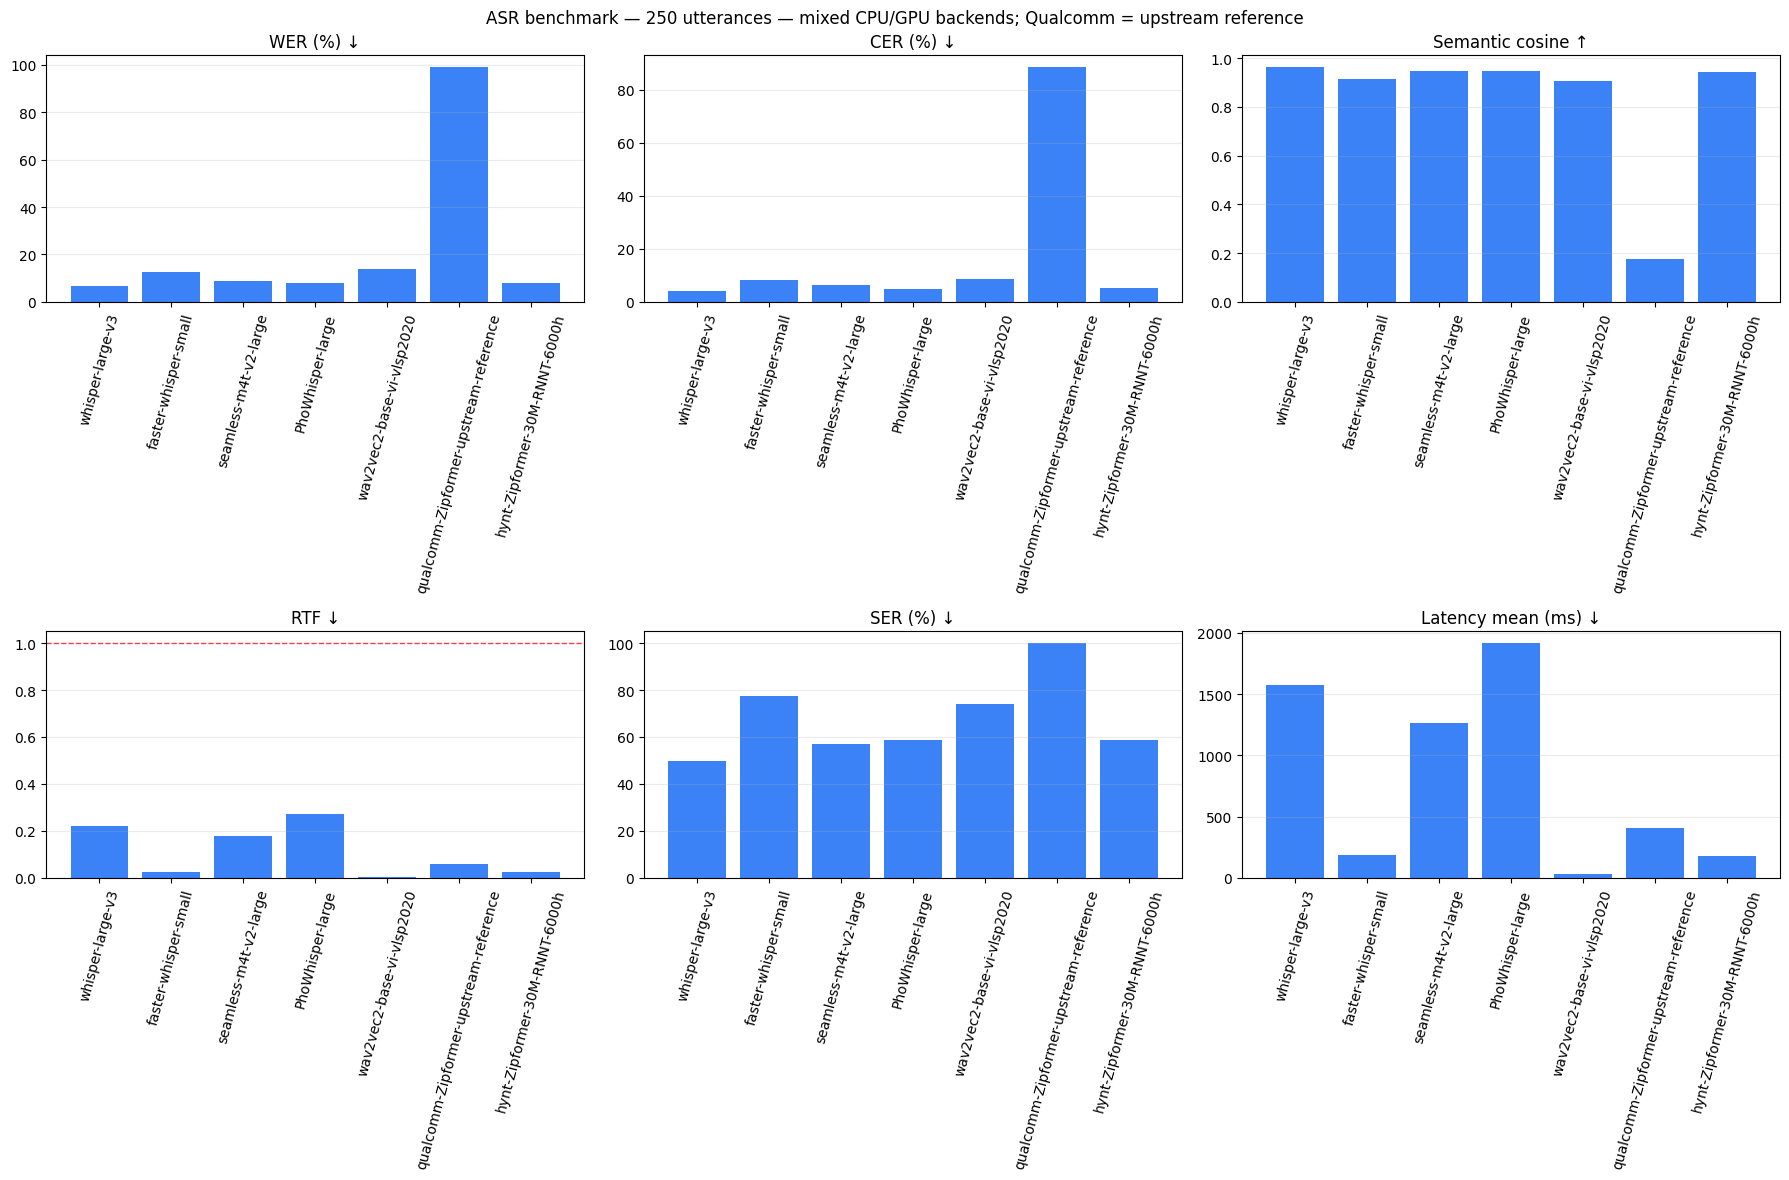

Kết quả: /content/drive/Shareddrives/Sudo Code 2026/full_v2/2f4970c3df775efb
CSV lưu tỷ lệ thô (0.1 = 10%); chỉ bảng hiển thị WER/CER/SER theo %.


In [12]:
def aggregate_metrics(frame):
    return {
        "wer": float(frame.word_errors.sum() / frame.reference_words.sum()),
        "cer": float(frame.char_errors.sum() / frame.reference_chars.sum()),
        "semantic_similarity": float(frame.semantic_similarity.mean()),
        "rtf": float(frame.latency_s.sum() / frame.duration_s.sum()),
        "ser": float(frame.sentence_error.mean()),
        "wer_basic": float(frame.word_errors_basic.sum() / frame.reference_words_basic.sum()),
        "cer_basic": float(frame.char_errors_basic.sum() / frame.reference_chars_basic.sum()),
        "latency_mean_s": float(frame.latency_s.mean()),
        "latency_mean_ms": float(frame.latency_s.mean() * 1000),
        "latency_median_ms": float(frame.latency_s.median() * 1000),
        "latency_p95_ms": float(frame.latency_s.quantile(0.95) * 1000),
        "latency_median_s": float(frame.latency_s.median()),
        "latency_p95_s": float(frame.latency_s.quantile(0.95)),
    }

metric_names = ["wer", "cer", "semantic_similarity", "rtf", "ser", "wer_basic", "cer_basic",
                "latency_mean_s", "latency_mean_ms", "latency_median_ms", "latency_p95_ms",
                "latency_median_s", "latency_p95_s"]
summary_rows, good_sets = [], []
model_by_name = {spec["name"]: spec for spec in MODEL_SPECS}
expected_ids = set(dataset.task_id)
for name in MODELS_TO_RUN:
    frame = predictions.loc[predictions.model.eq(name)]
    good = frame.loc[frame.status.eq("ok")]
    ids = set(good.task_id)
    good_sets.append(ids)
    complete = ids == expected_ids and len(good) == len(dataset) and good.semantic_similarity.notna().all()
    spec = model_by_name[name]
    model_status = "complete" if complete else "unsupported_on_colab" if len(frame) and frame.status.eq("unsupported_on_colab").all() else "incomplete"
    item = {"model": name, "requested_repo": spec["repo"],
            "weights_repo": spec.get("weights_repo", spec["repo"]),
            "inference_device": "Qualcomm NPU (unavailable)" if model_status == "unsupported_on_colab" else "cpu" if spec["kind"].startswith("zipformer_") else DEVICE,
            "backend": "QNN (required)" if model_status == "unsupported_on_colab" else "sherpa-onnx" if spec["kind"].startswith("zipformer_") else "CTranslate2" if spec["kind"] == "faster" else "Transformers",
            "deployment_scope": spec.get("deployment_scope", "original_checkpoint_colab"),
            "languages": spec.get("languages", "vi/multilingual"), "n_expected": len(dataset), "n_success": len(good),
            "n_failed_or_missing": len(expected_ids - ids), "coverage": len(ids) / len(expected_ids),
            "status": model_status,
            "audio_minutes_expected": float(dataset.duration_s.sum() / 60),
            "n_measurement_sessions": int(good.session_id.nunique()) if len(good) else 0,
            **{metric: None for metric in metric_names}}
    if complete:
        item.update(aggregate_metrics(good))
    summary_rows.append(item)
summary = pd.DataFrame(summary_rows)
summary.to_csv(RUN_DIR / "summary.csv", index=False, encoding="utf-8-sig")
predictions.to_csv(RUN_DIR / "predictions.csv", index=False, encoding="utf-8-sig")

common_ids = set.intersection(*good_sets) if good_sets else set()
common_rows = []
for name in MODELS_TO_RUN:
    frame = predictions.loc[predictions.model.eq(name) & predictions.task_id.isin(common_ids)]
    item = {"model": name, "n_common": len(common_ids), "scope": "intersection_of_successful_samples",
            **{metric: None for metric in metric_names}}
    if len(frame) and frame.semantic_similarity.notna().all():
        item.update(aggregate_metrics(frame))
    common_rows.append(item)
pd.DataFrame(common_rows).to_csv(RUN_DIR / "common_subset_summary.csv", index=False, encoding="utf-8-sig")

scenario_rows = []
for name in MODELS_TO_RUN:
    for scenario, expected in dataset.groupby("scenario_id"):
        frame = predictions.loc[predictions.model.eq(name) & predictions.scenario_id.eq(scenario)]
        good = frame.loc[frame.status.eq("ok")]
        complete = set(good.task_id) == set(expected.task_id) and good.semantic_similarity.notna().all()
        item = {"model": name, "scenario_id": scenario, "n_expected": len(expected),
                "n_success": len(good), "status": "complete" if complete else "incomplete",
                **{metric: None for metric in metric_names}}
        if complete:
            item.update(aggregate_metrics(good))
        scenario_rows.append(item)
pd.DataFrame(scenario_rows).to_csv(RUN_DIR / "scenario_summary.csv", index=False, encoding="utf-8-sig")

shown = summary[["model", "inference_device", "deployment_scope", "status", "n_success", "n_expected", "coverage", "wer", "cer",
                 "semantic_similarity", "rtf", "ser", "latency_mean_ms", "latency_median_ms", "latency_p95_ms"]].copy()
for column in ["coverage", "wer", "cer", "ser"]:
    shown[column] = shown[column] * 100
shown = shown.rename(columns={"coverage": "Coverage (%)", "wer": "WER (%)", "cer": "CER (%)",
                              "ser": "SER (%)", "semantic_similarity": "Semantic cosine", "rtf": "RTF",
                              "latency_mean_ms": "Latency mean (ms)", "latency_median_ms": "Latency median (ms)",
                              "latency_p95_ms": "Latency P95 (ms)"})
display(shown.round(4))
errors = predictions.loc[~predictions.status.eq("ok"), ["model", "task_id", "status", "error"]]
if not errors.empty:
    print("Có mẫu lỗi. Xem bảng này hoặc predictions.csv rồi chạy lại ô benchmark:")
    display(errors.head(20))

import matplotlib.pyplot as plt
complete_results = summary.loc[summary.status.eq("complete")]
if not complete_results.empty:
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()
    for axis, metric, label, scale in zip(axes,
        ["wer", "cer", "semantic_similarity", "rtf", "ser", "latency_mean_ms"],
        ["WER (%) ↓", "CER (%) ↓", "Semantic cosine ↑", "RTF ↓", "SER (%) ↓", "Latency mean (ms) ↓"], [100, 100, 1, 1, 100, 1]):
        axis.bar(complete_results.model, complete_results[metric] * scale, color="#3b82f6")
        axis.set_title(label)
        axis.tick_params(axis="x", labelrotation=75)
        axis.grid(axis="y", alpha=0.25)
        if metric == "rtf":
            axis.axhline(1, color="#ef4444", linestyle="--", linewidth=1)
    fig.suptitle(f"ASR benchmark — {len(dataset)} utterances — mixed CPU/GPU backends; Qualcomm = upstream reference")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "benchmark_metrics.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
print("Kết quả:", RUN_DIR)
print("CSV lưu tỷ lệ thô (0.1 = 10%); chỉ bảng hiển thị WER/CER/SER theo %.")


## 12. Đối chiếu các câu lỗi nhiều nhất
Chọn tên model để nghe và so sánh reference/hypothesis. Accuracy cao về ngữ nghĩa
vẫn có thể sai tên sản phẩm, giá tiền hoặc ý định mua; xem các câu này khi chọn model.


In [13]:
INSPECT_MODEL = "whisper-large-v3"
worst = predictions.loc[predictions.model.eq(INSPECT_MODEL) & predictions.status.eq("ok")]
if not worst.empty:
    worst = worst.sort_values(["wer", "cer"], ascending=False).head(10)
    display(worst[["task_id", "reference", "hypothesis", "wer", "cer", "semantic_similarity", "rtf", "latency_ms"]])
    for row in worst.head(3).to_dict("records"):
        print(row["task_id"], "\nREF:", row["reference"], "\nHYP:", row["hypothesis"])
        signal, sample_rate = RAW_AUDIO[row["task_id"]]
        display(Audio(signal.mean(axis=1), rate=sample_rate))


,task_id,reference,hypothesis,wer,cer,semantic_similarity,rtf,latency_ms
228,SC-037/call_2/3,"chị hiểu rồi, để xem thêm; chưa lên đơn và chư...",Hãy subscribe cho kênh Ghiền Mì Gõ Để không bỏ...,1.000000,0.978723,0.330737,0.332715,1357.477914
195,SC-033/call_1/1,"chị chỉ tham khảo, chưa đặt đơn. khi quay lại ...","Dạ rồi, tôi cảm ơn nhiều lắm. Chị chỉ tham khả...",0.388889,0.344262,0.697704,0.207737,2077.371041
54,SC-010/call_1/0,"alo, shop nghe rõ không? anh đang cân nhắc máy...","Alo, shop nghe rõ không? Anh đang kinh nhắc má...",0.375000,0.258621,0.804224,0.245451,1600.339575
171,SC-029/call_2/0,chị muốn xác nhận trước khi quyết. đơn odsáu t...,Chị muốn xác nhận trước khi quyết đơn O600-001...,0.347826,0.302326,0.890020,0.216965,1735.719323
161,SC-027/call_2/2,phí đổi size lần đầu thế nào? chị đồng ý làm t...,Chị đồng ý làm thủ tục đổi. Lấy hàng tại địa c...,0.333333,0.343750,0.863240,0.284735,1167.414297
31,SC-006/call_1/1,anh xem giá bảy triệu sáu trăm chín mươi nghìn...,Em kiểm tra giúp giá và hàng hiện tại nhé Ngân...,0.323529,0.336066,0.953275,0.130286,1516.526776
120,SC-021/call_1/0,"alo em, chị lấy giày sneaker urban classic, si...",tí giày sneaker Urban Classic size 38 màu trắng,0.285714,0.200000,0.908835,0.149169,793.581412
165,SC-028/call_2/0,anh liên hệ lại về lựa chọn đã trao đổi. đơn o...,quan tâm đến con cái. Anh liên hệ lại về lựa c...,0.269231,0.191011,0.872210,0.192682,2244.746704
227,SC-037/call_2/2,"nếu hàng chưa dùng, còn tem hộp và đổi size lầ...",Còn tem hộp và đổi size trên lần đầu thì chính...,0.263158,0.296875,0.881444,0.219038,1182.803985
224,SC-037/call_1/2,em ghi nhớ giúp sản phẩm này để lần sau mình k...,Em ghi nhớ để lần sau mình không phải nói lại ...,0.250000,0.269231,0.804217,0.212693,935.848091


SC-037/call_2/3 
REF: chị hiểu rồi, để xem thêm; chưa lên đơn và chưa hẹn gọi lại nhé. 
HYP: Hãy subscribe cho kênh Ghiền Mì Gõ Để không bỏ lỡ những video hấp dẫn


SC-033/call_1/1 
REF: chị chỉ tham khảo, chưa đặt đơn. khi quay lại chị sẽ hỏi thêm điều kiện đổi size. 
HYP: Dạ rồi, tôi cảm ơn nhiều lắm. Chị chỉ tham khảo, chưa đặt đơn. Khi quay lại, chị sẽ hỏi thêm điều kiện đổi size.


SC-010/call_1/0 
REF: alo, shop nghe rõ không? anh đang cân nhắc máy tiệt trùng sấy khô moaz bebe. 
HYP: Alo, shop nghe rõ không? Anh đang kinh nhắc máy kết chuồng sấy khô mát bê bê.


## 13. Tải kết quả và lưu notebook
Nếu dùng Drive, checkpoint và CSV đã nằm trong `RUN_DIR`. Ô dưới chỉ chạy khi muốn
tải ZIP báo cáo xuống máy; ZIP không chứa audio hay trọng số model.
Lưu một bản notebook sau khi chạy để giữ bảng/biểu đồ outputs.


In [15]:
DOWNLOAD_RESULTS = True
if DOWNLOAD_RESULTS:
    from google.colab import files
    archive = shutil.make_archive(f"/content/asr_results_{RUN_ID}", "zip", root_dir=RUN_DIR)
    files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Nguồn kỹ thuật và cách diễn giải
- [Whisper large-v3 model card](https://huggingface.co/openai/whisper-large-v3)
- [faster-whisper-small model card](https://huggingface.co/Systran/faster-whisper-small)
  và [SYSTRAN: inference, lazy generator, CUDA dependencies](https://github.com/SYSTRAN/faster-whisper)
- [SeamlessM4T v2 model card](https://huggingface.co/facebook/seamless-m4t-v2-large)
  và [Transformers v4.57.1: SpeechToText](https://huggingface.co/docs/transformers/v4.57.1/model_doc/seamless_m4t_v2)
- [PhoWhisper-large](https://huggingface.co/vinai/PhoWhisper-large)
- [Wav2Vec2 tiếng Việt: greedy/LM](https://huggingface.co/nguyenvulebinh/wav2vec2-base-vi-vlsp2020)
  và [feature_transform của tác giả](https://huggingface.co/nguyenvulebinh/wav2vec2-base-vi-vlsp2020/blob/main/model_handling.py)
- [Embedding model](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2)

Khi báo cáo, đính kèm cấu hình/normalization, tập mẫu được chọn, coverage, model SHA,
GPU, precision và backend. Beam 5 không khiến các decoder khác kiến trúc hoàn toàn tương đương.
So sánh RTF giữa runtime khác nhau cần chạy lại cùng điều kiện. Để đánh giá ổn định hơn,
tăng `TIMING_REPEATS` và chạy thêm các `RUN_TAG` độc lập trên cùng loại GPU.

Notebook đã kiểm tra cấu trúc và logic chuẩn bị dữ liệu/metric/checkpoint trên máy cục bộ;
chưa thực thi toàn bộ 7 mục model trên GPU Google Colab khi tạo file. Mọi số metric sẽ được
tính khi bạn chạy notebook; notebook không chứa kết quả benchmark giả định.


- [Qualcomm Zipformer: deployment assets và checkpoint upstream](https://huggingface.co/qualcomm/Zipformer)
  và [mã nguồn Qualcomm nạp pretrained.pt](https://github.com/qualcomm/ai-hub-models/blob/main/src/qai_hub_models/models/zipformer/model.py)
- [Checkpoint/ONNX upstream Trung–Anh](https://huggingface.co/pfluo/k2fsa-zipformer-chinese-english-mixed)
- [hynt Zipformer tiếng Việt](https://huggingface.co/hynt/Zipformer-30M-RNNT-6000h)
  và [token table mang tên config.json](https://huggingface.co/hynt/Zipformer-30M-RNNT-6000h/blob/main/config.json)
- [sherpa-onnx offline decode](https://github.com/k2-fsa/sherpa-onnx/blob/v1.12.40/python-api-examples/offline-decode-files.py)
  và [online decode/flush](https://github.com/k2-fsa/sherpa-onnx/blob/v1.12.40/python-api-examples/online-decode-files.py)

Không đưa số đo NPU Qualcomm từ model card vào bảng latency Colab: đó là các phép đo khác thiết bị,
có thể chỉ cho từng component và không phải thời gian nhận dạng toàn utterance tiếng Việt.
